## Follow-up Exploratory Analysis

For this checkpoint, I'll be looking at a few follow-up questions that came up from the earlier analysis. First, I want to see whether the relationship between IP address usage and phishing looks similar across our two datasets. Then, I want to look more closely at whether phishing and legitimate URLs differ in how many special characters they contain. These are exploratory comparisons, so I am mainly looking for patterns in the data.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff

Matplotlib is building the font cache; this may take a moment.


In [3]:
# Load the primary PhiUSIIL dataset

primary_path = Path("../datasets/PhiUSIIL_Phishing_URL_Dataset.csv")

if not primary_path.exists():
    primary_path = Path("datasets/PhiUSIIL_Phishing_URL_Dataset.csv")

primary_df = pd.read_csv(primary_path)


# Load the Website Phishing dataset

secondary_path = Path("../datasets/website-phishing/PhishingData.arff")

if not secondary_path.exists():
    secondary_path = Path("datasets/website-phishing/PhishingData.arff")

data, metadata = arff.loadarff(secondary_path)

secondary_df = pd.DataFrame(data)

# convert the ARFF byte strings into normal strings
for col in secondary_df.select_dtypes(include=["object"]).columns:
    secondary_df[col] = secondary_df[col].str.decode("utf-8")

#convert the coded features to integers
secondary_df = secondary_df.astype(int)


print("Primary dataset shape:", primary_df.shape)
print("Secondary dataset shape:", secondary_df.shape)

Primary dataset shape: (235795, 56)
Secondary dataset shape: (1353, 10)


### 1. IP Address Feature Across Both Datasets

The secondary analysis showed that the IP address feature may be related to phishing classification, so I wanted to see whether a similar pattern appears in the primary dataset.

The primary dataset only has phishing and legitimate classifications, while the secondary dataset also has a suspicious category. For this comparison, I will leave out the suspicious category so that both datasets are comparing phishing and legitimate websites.

In [4]:
# Keep only phishing and legitimate rows in the secondary dataset
secondary_binary = secondary_df[
    secondary_df["Result"].isin([-1, 1])
].copy()


# phishing rate by IP feature in the primary dataset
primary_ip = (
    primary_df.groupby("IsDomainIP")["label"]
    .apply(lambda x: (x == 0).mean() * 100)
    .reset_index(name="phishing_rate")
)

primary_ip["dataset"] = "PhiUSIIL"
primary_ip = primary_ip.rename(columns={"IsDomainIP": "ip_feature"})


#phishing rate by IP feature in the secondary dataset
secondary_ip = (
    secondary_binary.groupby("having_IP_Address")["Result"]
    .apply(lambda x: (x == -1).mean() * 100)
    .reset_index(name="phishing_rate")
)

secondary_ip["dataset"] = "Website Phishing"
secondary_ip = secondary_ip.rename(
    columns={"having_IP_Address": "ip_feature"}
)


#combine the summaries so they are easier to compare
ip_compare = pd.concat(
    [primary_ip, secondary_ip],
    ignore_index=True
)

display(ip_compare)

,ip_feature,phishing_rate,dataset
0,0,42.655332,PhiUSIIL
1,1,100.000000,PhiUSIIL
2,0,55.054152,Website Phishing
3,1,64.788732,Website Phishing


The table above gives the phishing percentage for each IP address feature value. A bar chart makes it easier to compare the pattern across the two datasets.

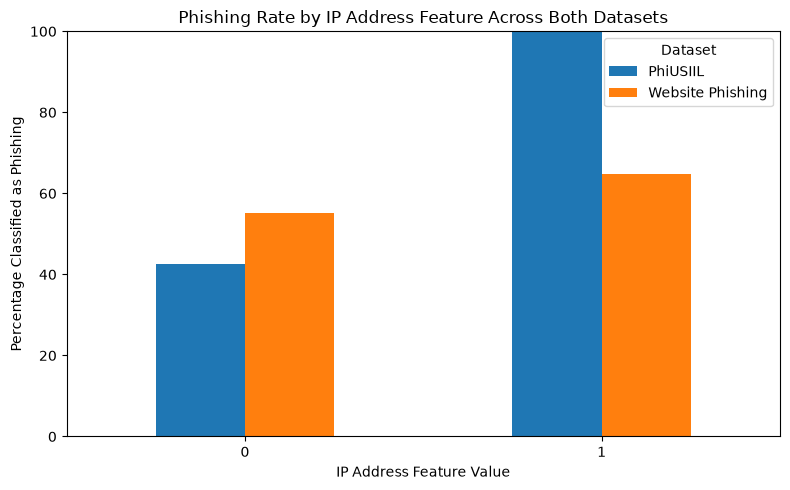

In [5]:
ip_plot = ip_compare.pivot(
    index="ip_feature",
    columns="dataset",
    values="phishing_rate"
)

ax = ip_plot.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Phishing Rate by IP Address Feature Across Both Datasets")
plt.xlabel("IP Address Feature Value")
plt.ylabel("Percentage Classified as Phishing")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Dataset")

plt.tight_layout()
plt.show()

In [6]:
print("PhiUSIIL IP feature counts:")
display(
    primary_df["IsDomainIP"]
    .value_counts()
    .sort_index()
)

print("Website Phishing IP feature counts:")
display(
    secondary_binary["having_IP_Address"]
    .value_counts()
    .sort_index()
)

PhiUSIIL IP feature counts:


IsDomainIP
0    235157
1       638
Name: count, dtype: int64

Website Phishing IP feature counts:


having_IP_Address
0    1108
1     142
Name: count, dtype: int64

#### What I noticed

Both datasets show a higher phishing rate when the IP address feature has a value of 1. In the PhiUSIIL dataset, about 43% of websites with `IsDomainIP = 0` are phishing, while 100% of websites with `IsDomainIP = 1` are phishing. However, there are only 638 websites with a value of 1 compared with 235,157 with a value of 0, so IP-based domains are very uncommon in this dataset.

The Website Phishing dataset shows the same general direction, but the difference is smaller. About 55% of websites with an IP feature value of 0 are phishing compared with about 65% when the value is 1.

#### So what?

It was interesting that both datasets showed a higher phishing rate for the IP address feature even though the size of the difference was not the same. At the same time, the PhiUSIIL result shows why it is important to look at counts along with percentages. The 100% phishing rate sounds very strong, but it comes from only 638 websites out of more than 235,000. This means the feature may be related to phishing, but it would not identify most phishing websites by itself.

#### What next?

A next step could be to see whether this pattern changes when the IP address feature is considered along with another characteristic, such as HTTPS or URL length. It would also be helpful to check the documentation for both datasets to make sure `IsDomainIP` and `having_IP_Address` represent the same idea before making a stronger comparison between them.


### 2. Special Characters in Phishing and Legitimate URLs

Next, I wanted to look more closely at the special-character ratio in URLs. The earlier analysis showed the overall distribution of this feature, but I wanted to directly compare phishing and legitimate websites. The `SpacialCharRatioInURL` column represents the proportion of special characters in each URL. I will compare this feature between phishing and legitimate URLs to see whether one group tends to have a higher ratio.

,count,mean,median,std,min,max
Phishing (0),100945,0.083,0.080,0.036,0.005,0.397
Legitimate (1),134850,0.048,0.042,0.019,0.000,0.231


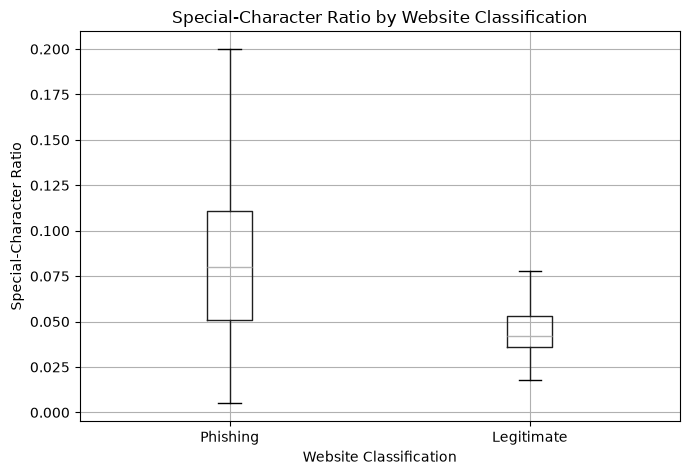

In [11]:
#The table gives a quick summary of the two groups. I also used a box plot so I could compare their centers and spreads more easily:

special_stats = (
    primary_df.groupby("label")["SpacialCharRatioInURL"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

special_stats.index = [
    "Phishing (0)",
    "Legitimate (1)"
]

display(special_stats.round(3))

primary_df.boxplot(
    column="SpacialCharRatioInURL",
    by="label",
    figsize=(7, 5),
    showfliers=False
)

plt.suptitle("")
plt.title("Special-Character Ratio by Website Classification")
plt.xlabel("Website Classification")
plt.ylabel("Special-Character Ratio")
plt.xticks(
    [1, 2],
    ["Phishing", "Legitimate"]
)

plt.tight_layout()
plt.show()

#### What I noticed

Phishing URLs generally have a higher special-character ratio than legitimate URLs. The median for phishing URLs is about 0.080, compared with about 0.042 for legitimate URLs. The phishing group also has a wider spread, which means there is more variation in the amount of special characters used.

The box plot shows a clear difference between the two groups, although there is still some overlap. This means special-character ratio may be related to phishing classification, but it cant separate every phishing URL from every legitimate URL.

#### So what?

This was a useful pattern because special characters are something that can actually appear directly in a URL and may make the URL look more unusual. At the same time, the overlap between the groups shows that this feature would not be enough by itself to decide whether a website is phishing. Some legitimate URLs also have higher special-character ratios, and some phishing URLs have lower ratios.

#### What next?

A next step could be to see whether the special-character ratio is still different between phishing and legitimate URLs when the URLs are around the same length. Since phishing URLs also tended to be longer, URL length could be related to part of the difference we are seeing here.

Another possible comparison would be to look at special-character ratios only among HTTPS websites.

### 3. Special-Character Ratio Within URL Length Groups

The previous analysis showed that phishing URLs tend to have higher special-character ratios than legitimate URLs. We also already know from the earlier group analysis that phishing URLs tend to be longer.

I wanted to check whether the difference in special-character ratio still appears when URLs are compared within similar length groups. I divided the URLs into short, medium, and long groups and compared phishing and legitimate websites within each group.

In [13]:
# Create simple URL length groups
primary_df["length_group"] = pd.cut(
    primary_df["URLLength"],
    bins=[0, 25, 40, float("inf")],
    labels=["Short (25 or less)", "Medium (26-40)", "Long (41+)"]
)

# Check how many phishing and legitimate URLs are in each group
length_counts = pd.crosstab(
    primary_df["length_group"],
    primary_df["label"]
)

length_counts.columns = ["Phishing", "Legitimate"]

display(length_counts)

,Phishing,Legitimate
length_group,,
Short (25 or less),24712,63992
Medium (26-40),40167,70060
Long (41+),36066,798


In [14]:
#Check the number of phishing and legitimate URLs in each length group so that we can see whether any of the groups were very small before comparing their special-character ratios.

length_special_stats = (
    primary_df.groupby(
        ["length_group", "label"],
        observed=True
    )["SpacialCharRatioInURL"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

length_special_stats["classification"] = (
    length_special_stats["label"]
    .map({
        0: "Phishing",
        1: "Legitimate"
    })
)

display(
    length_special_stats[
        ["length_group", "classification", "count", "mean", "median"]
    ].round(3)
)

,length_group,classification,count,mean,median
0,Short (25 or less),Phishing,24712,0.064,0.050
1,Short (25 or less),Legitimate,63992,0.053,0.045
2,Medium (26-40),Phishing,40167,0.081,0.077
3,Medium (26-40),Legitimate,70060,0.044,0.036
4,Long (41+),Phishing,36066,0.098,0.101
5,Long (41+),Legitimate,798,0.042,0.024


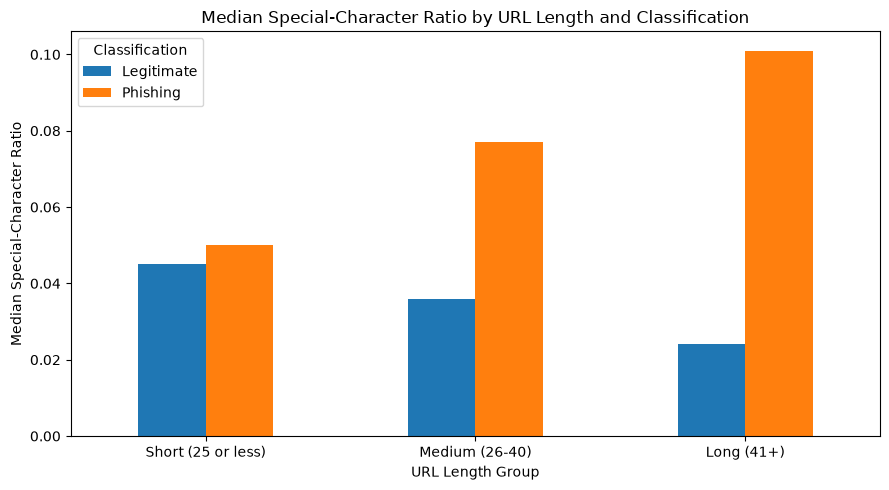

In [15]:
median_plot = (
    length_special_stats
    .pivot(
        index="length_group",
        columns="classification",
        values="median"
    )
)

ax = median_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Median Special-Character Ratio by URL Length and Classification")
plt.xlabel("URL Length Group")
plt.ylabel("Median Special-Character Ratio")
plt.xticks(rotation=0)
plt.legend(title="Classification")

plt.tight_layout()
plt.show()

#### What I noticed

The difference in special-character ratio still appears even when I compare URLs within similar length groups. For short URLs, the phishing and legitimate groups are fairly close, with median ratios of about 0.050 and 0.045. The difference becomes much larger for medium URLs, where the phishing median is about 0.077 compared with 0.036 for legitimate URLs. For long URLs, the difference is even larger, with a phishing median of about 0.101 compared with 0.024 for legitimate URLs.

One thing that stood out is that the long URL group is very unbalanced. There are 36,066 phishing URLs but only 798 legitimate URLs in that group, so that comparison should be interpreted carefully.

#### So what?

This suggests that the higher special-character ratio among phishing URLs is not only happening because phishing URLs tend to be longer. Even within the same general length groups, phishing URLs usually have higher special-character ratios. The pattern is weakest for short URLs and becomes stronger for medium and long URLs. This could mean that unusual URL structure becomes more noticeable among longer phishing URLs, although this analysis only shows an association and does not explain why the pattern happens.

### What's next?

A next step could be to look more closely at which kinds of special characters are creating this difference. It could also be useful to compare medium-length URLs more closely because both phishing and legitimate websites have many observations in that group, making it a more balanced comparison than the long URL group.

#### Most notable findings from this EDA:

1) Both datasets showed a higher phishing rate when the IP address feature was present, although the pattern was much stronger in PhiUSIIL. Looking at the counts also showed that IP-based domains were very rare, so the feature would not identify most phishing websites by itself.

2) Phishing URLs generally had higher special-character ratios than legitimate URLs. This difference was still visible when URLs were split into short, medium, and long groups, so the pattern does not seem to come only from phishing URLs being longer.
